<a href="https://colab.research.google.com/github/FragileMouse/5_lab_teor_system/blob/main/%D0%9B%D0%B0%D0%B1_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

Загрузим данные.

In [2]:
url = 'https://raw.githubusercontent.com/FragileMouse/5_lab_teor_system/refs/heads/main/%D0%94%D0%B0%D0%BD%D0%BD%D1%8B%D0%B5%20%D0%B4%D0%BB%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D1%8B.csv'

data = pd.read_csv(url)
data.head()

,region_name,region_code,indicator_name,measure_unit,2018,2019,2020,2021,2022,2023,2024
0,Российская Федерация,6.430000e+02,Численность отдохнувших детей в субъекте Росси...,тысяч человек,4274.4,4331.4,707.1,3597.548,3925.2,4021.612,4086.1
1,Центральный федеральный округ,3.000000e+01,Численность отдохнувших детей в субъекте Росси...,тысяч человек,742.0,764.0,168.2,676.677,720.6,704.461,697.0
2,Белгородская область,1.400000e+10,Численность отдохнувших детей в субъекте Росси...,тысяч человек,80.2,82.4,16.2,95.502,89.6,59.516,40.2
3,Брянская область,1.500000e+10,Численность отдохнувших детей в субъекте Росси...,тысяч человек,36.4,37.6,17.8,32.822,32.9,33.145,32.6
4,Владимирская область,1.700000e+10,Численность отдохнувших детей в субъекте Росси...,тысяч человек,46.7,46.6,-,40.726,45.7,46.285,48.4


- region_name — название территории;
- region_code — код территории;
- indicator_name — название показателя;
- measure_unit — единица измерения, здесь «тысяч человек»;
- 2018–2024 — значения показателя по годам.

Приведем к более понятному виду.

In [3]:
years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024']
data = data[['region_name'] + years]
data.head()

,region_name,2018,2019,2020,2021,2022,2023,2024
0,Российская Федерация,4274.4,4331.4,707.1,3597.548,3925.2,4021.612,4086.1
1,Центральный федеральный округ,742.0,764.0,168.2,676.677,720.6,704.461,697.0
2,Белгородская область,80.2,82.4,16.2,95.502,89.6,59.516,40.2
3,Брянская область,36.4,37.6,17.8,32.822,32.9,33.145,32.6
4,Владимирская область,46.7,46.6,-,40.726,45.7,46.285,48.4


Теперь нам надо оставить только регионы

In [5]:
print(data['region_name'].unique())

['Российская Федерация' 'Центральный федеральный округ'
 'Белгородская область' 'Брянская область' 'Владимирская область'
 'Воронежская область' 'Ивановская область' 'Калужская область'
 'Костромская область' 'Курская область' 'Липецкая область'
 'Московская область' 'Орловская область' 'Рязанская область'
 'Смоленская область' 'Тамбовская область' 'Тверская область'
 'Тульская область' 'Ярославская область' 'г. Москва'
 'Северо-Западный федеральный округ' 'Республика Карелия'
 'Республика Коми' 'Архангельская область' 'Ненецкий автономный округ'
 'Архангельская область без автономного округа' 'Вологодская область'
 'Калинингpадская область' 'Ленинградская область' 'Мурманская область'
 'Новгородская область' 'Псковская область' 'г. Санкт-Петербург'
 'Южный федеральный округ' 'Республика Адыгея' 'Республика Калмыкия'
 'Республика Крым' 'Краснодарский край' 'Астраханская область'
 'Волгоградская область' 'Ростовская область' 'г. Севастополь'
 'Северо-Кавказский федеральный округ' 'Респу

In [6]:
remove_names = [
    'Российская Федерация',
    'Центральный федеральный округ',
    'Северо-Западный федеральный округ',
    'Южный федеральный округ',
    'Северо-Кавказский федеральный округ',
    'Приволжский федеральный округ',
    'Уральский федеральный округ',
    'Сибирский федеральный округ',
    'Дальневосточный федеральный округ',
    'Архангельская область',
    'Тюменская область'
]

data = data[~data['region_name'].isin(remove_names)].copy()

data = data[
    ~data['region_name'].str.startswith('___________', na=False)
].copy()

data.head()


,region_name,2018,2019,2020,2021,2022,2023,2024
2,Белгородская область,80.2,82.4,16.2,95.502,89.6,59.516,40.2
3,Брянская область,36.4,37.6,17.8,32.822,32.9,33.145,32.6
4,Владимирская область,46.7,46.6,-,40.726,45.7,46.285,48.4
5,Воронежская область,61.2,62.4,15.1,47.825,62.8,69.368,68.5
6,Ивановская область,21.2,21.3,0.6,23.168,25.7,25.393,25.9


In [7]:
data['region_name'].unique()

array(['Белгородская область', 'Брянская область', 'Владимирская область',
       'Воронежская область', 'Ивановская область', 'Калужская область',
       'Костромская область', 'Курская область', 'Липецкая область',
       'Московская область', 'Орловская область', 'Рязанская область',
       'Смоленская область', 'Тамбовская область', 'Тверская область',
       'Тульская область', 'Ярославская область', 'г. Москва',
       'Республика Карелия', 'Республика Коми',
       'Ненецкий автономный округ',
       'Архангельская область без автономного округа',
       'Вологодская область', 'Калинингpадская область',
       'Ленинградская область', 'Мурманская область',
       'Новгородская область', 'Псковская область', 'г. Санкт-Петербург',
       'Республика Адыгея', 'Республика Калмыкия', 'Республика Крым',
       'Краснодарский край', 'Астраханская область',
       'Волгоградская область', 'Ростовская область', 'г. Севастополь',
       'Республика Дагестан', 'Республика Ингушетия',
     

Как мы могли заметить, пропущенные значения обозначаются симловом '-'. Сначала приведем их все в Nan

In [8]:
for year in years:
    data[year] = pd.to_numeric(data[year], errors='coerce')

data.head()

,region_name,2018,2019,2020,2021,2022,2023,2024
2,Белгородская область,80.2,82.4,16.2,95.502,89.6,59.516,40.2
3,Брянская область,36.4,37.6,17.8,32.822,32.9,33.145,32.6
4,Владимирская область,46.7,46.6,NaN,40.726,45.7,46.285,48.4
5,Воронежская область,61.2,62.4,15.1,47.825,62.8,69.368,68.5
6,Ивановская область,21.2,21.3,0.6,23.168,25.7,25.393,25.9


In [10]:
clean_data = data.dropna()

clean_data.head()

,region_name,2018,2019,2020,2021,2022,2023,2024
2,Белгородская область,80.2,82.4,16.2,95.502,89.6,59.516,40.2
3,Брянская область,36.4,37.6,17.8,32.822,32.9,33.145,32.6
5,Воронежская область,61.2,62.4,15.1,47.825,62.8,69.368,68.5
6,Ивановская область,21.2,21.3,0.6,23.168,25.7,25.393,25.9
8,Костромская область,21.6,21.9,16.3,20.858,21.5,25.057,27.2


In [11]:
print('Новая:', clean_data.shape)
print('Cтарая:', data.shape)

Новая: (55, 8)
Cтарая: (85, 8)


Перейдем к стандартизации

In [15]:
data_prepared = clean_data.set_index('region_name')
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_prepared)

In [17]:
scaled_data

array([[ 0.48134597,  0.50978265,  0.22368454,  1.15375549,  0.8294473 ,
         0.10688953, -0.34806412],
       [-0.46523562, -0.45749322,  0.33083881, -0.41422614, -0.48303058,
        -0.50277378, -0.52172228],
       [ 0.07072839,  0.07796306,  0.15001598, -0.03891618,  0.20908738,
         0.33465499,  0.29858401],
       [-0.79372968, -0.80942618, -0.82106959, -0.65572734, -0.64969443,
        -0.68198997, -0.67481565],
       [-0.7850851 , -0.79647159,  0.23038168, -0.71351351, -0.74691502,
        -0.68975785, -0.64511097],
       [-0.5171031 , -0.53737984,  0.60542162, -0.27851618, -0.50154878,
        -0.59862392, -0.61540628],
       [-0.25128224, -0.28260629,  0.42459879, -0.28209342, -0.2700712 ,
        -0.256444  , -0.2749449 ],
       [ 0.99353738,  1.15319383,  0.7460616 ,  0.92881466,  1.25536604,
         1.15381999,  1.22171421],
       [-0.70728388, -0.75544873, -0.84116102, -0.70203132, -0.73302636,
        -0.72062132, -0.73879497],
       [-0.69647815, -0.7057

Применим кластерный анализ и визуализируем результаты



In [18]:
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(scaled_data)
cluster_labels = kmeans.labels_

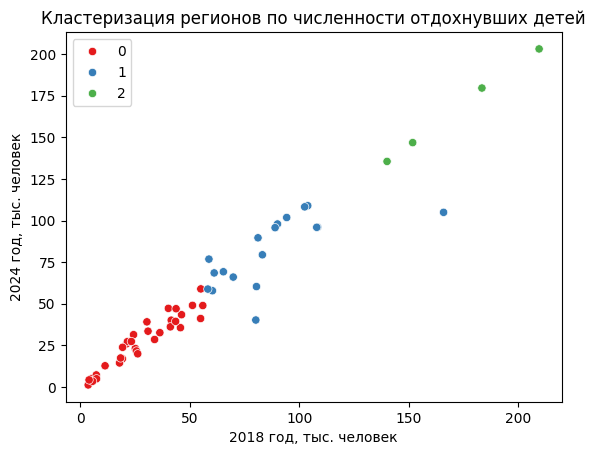

In [20]:
sns.scatterplot(
    x=clean_data['2018'],
    y=clean_data['2024'],
    hue=cluster_labels,
    palette='Set1'
)

plt.xlabel('2018 год, тыс. человек')
plt.ylabel('2024 год, тыс. человек')
plt.title('Кластеризация регионов по численности отдохнувших детей')
plt.show()

In [21]:
clustered_data = clean_data.copy()
clustered_data['Cluster'] = cluster_labels
clustered_data.head()

,region_name,2018,2019,2020,2021,2022,2023,2024,Cluster
2,Белгородская область,80.2,82.4,16.2,95.502,89.6,59.516,40.2,1
3,Брянская область,36.4,37.6,17.8,32.822,32.9,33.145,32.6,0
5,Воронежская область,61.2,62.4,15.1,47.825,62.8,69.368,68.5,1
6,Ивановская область,21.2,21.3,0.6,23.168,25.7,25.393,25.9,0
8,Костромская область,21.6,21.9,16.3,20.858,21.5,25.057,27.2,0


In [24]:
cluster_means = clustered_data.groupby('Cluster').mean(numeric_only=True)
cluster_means

,2018,2019,2020,2021,2022,2023,2024
Cluster,,,,,,,
0,28.484848,28.687879,7.624242,24.124636,26.251515,26.829394,27.512121
1,86.733333,89.122222,17.916667,72.251444,78.933333,81.946944,81.994444
2,171.200000,170.625000,33.300000,154.824500,167.525000,164.668000,166.250000


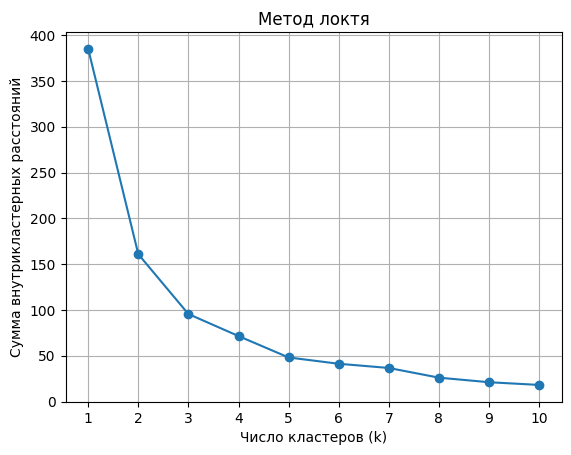

In [25]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)


plt.plot(range(1, 11), inertia, marker='o')
plt.title("Метод локтя")
plt.xlabel("Число кластеров (k)")
plt.ylabel("Сумма внутрикластерных расстояний")
plt.xticks(range(1, 11))
plt.grid()
plt.show()


In [30]:
region_clusters = data.loc[clean_data.index, ['region_name']].copy()
region_clusters['Cluster'] = cluster_labels
region_clusters.sort_values('Cluster')

for cluster in sorted(region_clusters['Cluster'].unique()):
    print(f'\nКластер {cluster}:')
    for region in region_clusters[region_clusters['Cluster'] == cluster]['region_name'].to_list():
      print(' - ', region)


Кластер 0:
 -  Брянская область
 -  Ивановская область
 -  Костромская область
 -  Курская область
 -  Липецкая область
 -  Орловская область
 -  Рязанская область
 -  Тамбовская область
 -  Тверская область
 -  Ярославская область
 -  г. Москва
 -  Республика Карелия
 -  Республика Коми
 -  Вологодская область
 -  Калинингpадская область
 -  Мурманская область
 -  Новгородская область
 -  Псковская область
 -  г. Санкт-Петербург
 -  Астраханская область
 -  г. Севастополь
 -  Кабардино-Балкарская Республика
 -  Республика Марий Эл
 -  Кировская область
 -  Пензенская область
 -  Курганская область
 -  Республика Тыва
 -  Республика Саха (Якутия)
 -  Забайкальский край
 -  Хабаровский край
 -  Амурская область
 -  Сахалинская область
 -  Чукотский автономный округ

Кластер 1:
 -  Белгородская область
 -  Воронежская область
 -  Московская область
 -  Ленинградская область
 -  Республика Крым
 -  Волгоградская область
 -  Ростовская область
 -  Удмуртская Республика
 -  Пермский край
 